# Ranking evaluation: weighted dot product vs cosine similarity

**Goal:** Compare M1 variants alone and with M3 BM25, M4 MiniLM, and RRF fusion using the evaluation history. Includes strict cohort separation, repeat-run handling, performance charts, and fair paired-condition comparisons.

**Files:** This notebook ships with `ranking_evaluation_history_clean.csv`, reconstructed from the supplied history pasted as Markdown. To use the live repository history, change `CSV_PATH` to `reports/ranking/evaluation_history.csv`. Re-run all cells after appending new experiments.

> **Important:** These aggregate metrics are not sufficient for per-profile confidence intervals or claims of statistical significance. A CSV history row is a run, not an independent profile. Do not combine oracle profiles and mock-tracker sessions, or distinct dataset fingerprints, in a single performance comparison.

In [1]:
%pip install numpy
%pip install pandas
%pip install matplotlib
%pip install seaborn
%pip install IPython

Note: you may need to restart the kernel to use updated packages.
  Using cached pandas-3.0.6-cp313-cp313-win_amd64.whl.metadata (19 kB)
  Using cached tzdata-2026.5-py2.py3-none-any.whl.metadata (1.4 kB)
Using cached pandas-3.0.6-cp313-cp313-win_amd64.whl (9.6 MB)
Using cached tzdata-2026.5-py2.py3-none-any.whl (347 kB)

   ---------------------------------------- 0/2 [tzdata]
   -------------------- ------------------- 1/2 [pandas]
   -------------------- ------------------- 1/2 [pandas]
   -------------------- ------------------- 1/2 [pandas]
   -------------------- ------------------- 1/2 [pandas]
   -------------------- ------------------- 1/2 [pandas]
   -------------------- ------------------- 1/2 [pandas]
   -------------------- ------------------- 1/2 [pandas]
   -------------------- ------------------- 1/2 [pandas]
   -------------------- ------------------- 1/2 [pandas]
   -------------------- ------------------- 1/2 [pandas]
   -------------------- ------------------- 1/2 [

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

CSV_PATH = Path("ranking_evaluation_history_clean.csv")  # change to your repository CSV as needed
METRICS = ["hit_at_1", "hit_at_5", "hit_at_10", "mrr", "ndcg_at_5", "ndcg_at_10"]
METRIC_LABELS = {"hit_at_1":"Hit@1", "hit_at_5":"Hit@5", "hit_at_10":"Hit@10", "mrr":"MRR", "ndcg_at_5":"NDCG@5", "ndcg_at_10":"NDCG@10"}
plt.rcParams.update({"figure.figsize": (11, 5), "axes.grid": True, "grid.alpha": 0.2})


## 1. Load and normalize history

- Component identity is taken from the `m1`, `m3`, `m4`, and `fusion` columns (not the report folder name).
- Legacy `weighted_dot_product` and `weighted_dot_product@baseline_v1` are grouped as the same scoring family while preserving their original names.
- The history does **not** contain full relevance labels, per-profile ranks, upstream provenance or all evaluation settings. It is a descriptive index, not a substitute for the per-run manifests.

In [3]:
def load_history(path=CSV_PATH):
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(f"Could not find {path.resolve()}. Change CSV_PATH to your history file.")
    df = pd.read_csv(path, dtype={"run_id":"string", "dataset_fingerprint":"string"}, keep_default_na=False)
    required = {"run_id", "timestamp", "m1", "m3", "m4", "fusion", "candidate_count", "profile_count", "dataset_fingerprint", *METRICS}
    missing = required - set(df.columns)
    if missing:
        raise ValueError(f"Missing required columns: {sorted(missing)}")
    for col in ["m1", "m3", "m4", "fusion"]:
        df[col] = df[col].fillna("").astype(str).str.strip()
    for col in METRICS + ["candidate_count", "profile_count"]:
        df[col] = pd.to_numeric(df[col], errors="coerce")
    df["timestamp"] = pd.to_datetime(df["timestamp"], errors="coerce", utc=True)
    df["m1_method"] = np.select(
        [df.m1.str.startswith("weighted_dot_product"), df.m1.str.startswith("cosine_similarity"), df.m1.eq("")],
        ["Dot product", "Cosine", "None"], default="Other")
    df["bm25"] = df.m3.str.contains("bm25", case=False)
    df["minilm"] = df.m4.str.contains("minilm", case=False)
    df["extras"] = np.select(
        [df.bm25 & df.minilm, df.bm25, df.minilm],
        ["BM25 + MiniLM", "BM25", "MiniLM"], default="None")
    df["configuration"] = df["m1_method"] + " + " + df["extras"]
    df.loc[df.extras.eq("None"), "configuration"] = df.loc[df.extras.eq("None"), "m1_method"]
    df["cohort"] = np.select(
        [df.run_id.str.startswith("m2_structured_oracle"), df.run_id.str.startswith("m5_mock_tracker"), df.run_id.str.startswith("m6_stress")],
        ["Oracle development", "M5 mock tracker", "M6 mock stress"], default="Other / inspect")
    df["evidence_policy"] = df.description.fillna("").astype(str).str.extract(r"evidence_filter=(raw|active_only)", expand=False).fillna("unspecified")
    df.loc[df.cohort.eq("Oracle development"), "evidence_policy"] = "raw"
    return df

history = load_history()
print(f"Loaded {len(history)} history runs from {CSV_PATH}")
display(history.groupby(["cohort","dataset_fingerprint","candidate_count","profile_count"], dropna=False).size().reset_index(name="runs"))


Loaded 24 history runs from ranking_evaluation_history_clean.csv


,cohort,dataset_fingerprint,candidate_count,profile_count,runs
0,M5 mock tracker,312e2023ee6511333bbfa4c37f88d2bf3a3315f9a2c20e...,378,2,2
1,M6 mock stress,cb11736640cdb6b3561d2f919a222ebafd150004742080...,378,60,6
2,Oracle development,a8ac34541c4e07144a7133d004d2463512c328b869deaf...,378,60,15
3,Oracle development,db255210bf9193e0f8378146b421d576f9fe2e0fe29fd9...,378,60,1


## 2. Choose a comparable evaluation cohort

By default, select the **latest oracle-development fingerprint with both dot-product and cosine runs**. The comparison is restricted to the same fingerprint, cohort, candidate count, and profile count. Repeated reruns of the same component configuration are reduced to the latest run. This avoids artificially weighting a configuration just because it was executed repeatedly.

If experiments use different input policies or hidden parameter versions despite identical CSV identifiers, inspect saved manifests before claiming a valid paired comparison.

In [4]:
def choose_comparison_cohort(df):
    oracle = df[(df.cohort == "Oracle development") & df.m1_method.isin(["Dot product", "Cosine"])].copy()
    keys = ["dataset_fingerprint", "candidate_count", "profile_count"]
    eligible = []
    for key, group in oracle.groupby(keys, dropna=False):
        if {"Dot product", "Cosine"}.issubset(set(group.m1_method)):
            eligible.append((group.timestamp.max(), key))
    if not eligible:
        raise ValueError("No shared oracle dataset fingerprint containing both methods; do NOT compare across fingerprints automatically.")
    eligible.sort(key=lambda t: t[0])
    return dict(zip(keys, eligible[-1][1]))

SELECTED = choose_comparison_cohort(history)
print("Selected matched cohort:", SELECTED)

def filter_cohort(df, cohort="Oracle development", dataset_fingerprint=None, candidate_count=None, profile_count=None):
    out = df[df.cohort.eq(cohort)].copy()
    for field, value in {"dataset_fingerprint":dataset_fingerprint, "candidate_count":candidate_count, "profile_count":profile_count}.items():
        if value is not None:
            out = out[out[field].eq(value)]
    return out

cohort = filter_cohort(history, **SELECTED)

def latest_config_runs(df):
    identity = ["m1_method", "m3", "m4", "fusion", "evidence_policy"]
    return df.sort_values("timestamp").drop_duplicates(identity, keep="last").copy()

selected = latest_config_runs(cohort[cohort.m1_method.isin(["Dot product", "Cosine"])])
print(f"Matched raw runs: {len(cohort)}; unique configurations: {len(selected)}")
display(selected.sort_values(["m1_method", "extras"])[["configuration", "m1", "m3", "m4", "fusion", "profile_count"]+METRICS].reset_index(drop=True))


Selected matched cohort: {'dataset_fingerprint': 'a8ac34541c4e07144a7133d004d2463512c328b869deafcd54b22cbfddc29331', 'candidate_count': 378, 'profile_count': 60}
Matched raw runs: 15; unique configurations: 8


,configuration,m1,m3,m4,fusion,profile_count,hit_at_1,hit_at_5,hit_at_10,mrr,ndcg_at_5,ndcg_at_10
0,Cosine + BM25,cosine_similarity@baseline_v1,bm25@baseline_v1,,rrf_k60,60,0.133333,0.266667,0.400000,0.214472,0.166854,0.189500
1,Cosine + BM25 + MiniLM,cosine_similarity@baseline_v1,bm25@baseline_v1,minilm@mean_tasks_v1,rrf_k60,60,0.033333,0.116667,0.216667,0.101065,0.080535,0.100519
2,Cosine + MiniLM,cosine_similarity@baseline_v1,,minilm@mean_tasks_v1,rrf_k60,60,0.083333,0.233333,0.466667,0.189187,0.153833,0.195790
3,Cosine,cosine_similarity@baseline_v1,,,,60,0.583333,0.883333,0.966667,0.713695,0.537513,0.528027
4,Dot product + BM25,weighted_dot_product@baseline_v1,bm25@baseline_v1,,rrf_k60,60,0.016667,0.133333,0.200000,0.084887,0.098101,0.116610
5,Dot product + BM25 + MiniLM,weighted_dot_product@baseline_v1,bm25@baseline_v1,minilm@mean_tasks_v1,rrf_k60,60,0.000000,0.050000,0.116667,0.045221,0.051315,0.068509
6,Dot product + MiniLM,weighted_dot_product@baseline_v1,,minilm@mean_tasks_v1,rrf_k60,60,0.016667,0.116667,0.200000,0.086552,0.103499,0.121640
7,Dot product,weighted_dot_product@baseline_v1,,,,60,0.033333,0.166667,0.433333,0.135636,0.151459,0.203471


## 3. Reusable presentation functions

`show_results`, `plot_grouped_metrics`, `plot_method_heatmap`, `compare_structured_methods`, `plot_fusion_impact`, and `plot_metric_profile` work on any appropriately filtered history dataframe.

In [5]:
EXTRA_ORDER = ["None", "BM25", "MiniLM", "BM25 + MiniLM"]
METHOD_ORDER = ["Dot product", "Cosine"]

def show_results(df, metrics=METRICS):
    cols = ["m1_method", "extras", "fusion", "profile_count"] + list(metrics)
    shown = df[cols].sort_values(["m1_method", "extras"]).copy()
    return shown.style.format({metric:"{:.1%}" for metric in metrics}).background_gradient(subset=list(metrics), cmap="Blues")

def plot_grouped_metrics(df, metrics=("hit_at_5", "mrr")):
    fig, axes = plt.subplots(1, len(metrics), figsize=(max(6, 6*len(metrics)), 5), squeeze=False)
    for ax, metric in zip(axes[0], metrics):
        data = df[df.m1_method.isin(METHOD_ORDER)]
        sns.barplot(data=data, x="extras", y=metric, hue="m1_method", order=EXTRA_ORDER, hue_order=METHOD_ORDER, ax=ax, errorbar=None)
        ax.set_title(METRIC_LABELS.get(metric,metric)); ax.set_xlabel("Additional retrieval components"); ax.set_ylabel("Metric value")
        ax.tick_params(axis="x", rotation=15)
        ax.set_ylim(0, max(.05, data[metric].max()*1.16))
    plt.tight_layout(); plt.show()

def plot_method_heatmap(df, metric="hit_at_5"):
    data = df[df.m1_method.isin(METHOD_ORDER)].pivot_table(index="m1_method", columns="extras", values=metric, aggfunc="mean").reindex(index=METHOD_ORDER, columns=EXTRA_ORDER)
    fig, ax = plt.subplots(figsize=(9, 3.4))
    sns.heatmap(data, annot=True, fmt=".1%", cmap="Blues", vmin=0, vmax=1, linewidths=.5, ax=ax, mask=data.isna())
    ax.set_title(METRIC_LABELS.get(metric, metric) + " — structured method × retrieval combination")
    ax.set_xlabel("Added channels"); ax.set_ylabel("M1 scoring")
    plt.tight_layout(); plt.show()
    return data

def compare_structured_methods(df, metrics=METRICS):
    result = df[df.m1_method.isin(METHOD_ORDER)].pivot_table(index="extras", columns="m1_method", values=list(metrics), aggfunc="mean")
    pieces = []
    for metric in metrics:
        dot = result.get((metric,"Dot product"), pd.Series(dtype=float))
        cos = result.get((metric,"Cosine"), pd.Series(dtype=float))
        pairs = pd.DataFrame({"extras":EXTRA_ORDER}).set_index("extras")
        pairs["dot"] = dot; pairs["cosine"] = cos
        pairs["delta_cosine_minus_dot"] = pairs["cosine"] - pairs["dot"]
        pairs["metric"] = METRIC_LABELS[metric]
        pieces.append(pairs.reset_index())
    return pd.concat(pieces, ignore_index=True)[["metric","extras","dot","cosine","delta_cosine_minus_dot"]]

def plot_fusion_impact(df, metric="hit_at_5"):
    data = df[df.m1_method.isin(METHOD_ORDER)].copy()
    base = data[data.extras.eq("None")].groupby("m1_method")[metric].mean()
    data["delta_from_standalone"] = data.apply(lambda row: row[metric]-base.get(row.m1_method, np.nan), axis=1)
    data = data[~data.extras.eq("None")]
    fig,ax=plt.subplots(figsize=(10,4.8))
    sns.barplot(data=data, x="extras", y="delta_from_standalone", hue="m1_method", order=EXTRA_ORDER[1:], hue_order=METHOD_ORDER, ax=ax, errorbar=None)
    ax.axhline(0, color="black", linewidth=1)
    ax.set_title(f"Effect of adding retrieval channels on {METRIC_LABELS.get(metric, metric)}")
    ax.set_ylabel("Absolute change (metric points)"); ax.set_xlabel("Added channels")
    plt.tight_layout(); plt.show()

def plot_metric_profile(df, extras="None"):
    sub = df[(df.extras == extras) & df.m1_method.isin(METHOD_ORDER)]
    if sub.empty:
        print("No matching configurations"); return
    long = sub.melt(id_vars="m1_method", value_vars=METRICS, var_name="metric", value_name="value")
    long["metric"] = long.metric.map(METRIC_LABELS)
    fig, ax=plt.subplots(figsize=(10,5))
    sns.barplot(data=long, x="metric", y="value", hue="m1_method", hue_order=METHOD_ORDER, ax=ax, errorbar=None)
    ax.set_title(f"Metric profile — added channels: {extras}")
    ax.set_ylim(0, 1); ax.set_ylabel("Metric value"); ax.set_xlabel("")
    plt.tight_layout(); plt.show()


## 4. Dashboard: all configurations on the matching oracle cohort

In [7]:
%pip install jinja2

  Using cached jinja2-3.1.6-py3-none-any.whl.metadata (2.9 kB)
  Using cached markupsafe-3.0.4-cp313-cp313-win_amd64.whl.metadata (2.8 kB)
Using cached jinja2-3.1.6-py3-none-any.whl (134 kB)
Using cached markupsafe-3.0.4-cp313-cp313-win_amd64.whl (14 kB)

   -------------------- ------------------- 1/2 [jinja2]
   ---------------------------------------- 2/2 [jinja2]

Note: you may need to restart the kernel to use updated packages.


,m1_method,extras,fusion,profile_count,hit_at_1,hit_at_5,hit_at_10,mrr,ndcg_at_5,ndcg_at_10
21,Cosine,BM25,rrf_k60,60,13.3%,26.7%,40.0%,21.4%,16.7%,18.9%
23,Cosine,BM25 + MiniLM,rrf_k60,60,3.3%,11.7%,21.7%,10.1%,8.1%,10.1%
22,Cosine,MiniLM,rrf_k60,60,8.3%,23.3%,46.7%,18.9%,15.4%,19.6%
20,Cosine,None,,60,58.3%,88.3%,96.7%,71.4%,53.8%,52.8%
6,Dot product,BM25,rrf_k60,60,1.7%,13.3%,20.0%,8.5%,9.8%,11.7%
10,Dot product,BM25 + MiniLM,rrf_k60,60,0.0%,5.0%,11.7%,4.5%,5.1%,6.9%
8,Dot product,MiniLM,rrf_k60,60,1.7%,11.7%,20.0%,8.7%,10.3%,12.2%
19,Dot product,None,,60,3.3%,16.7%,43.3%,13.6%,15.1%,20.3%


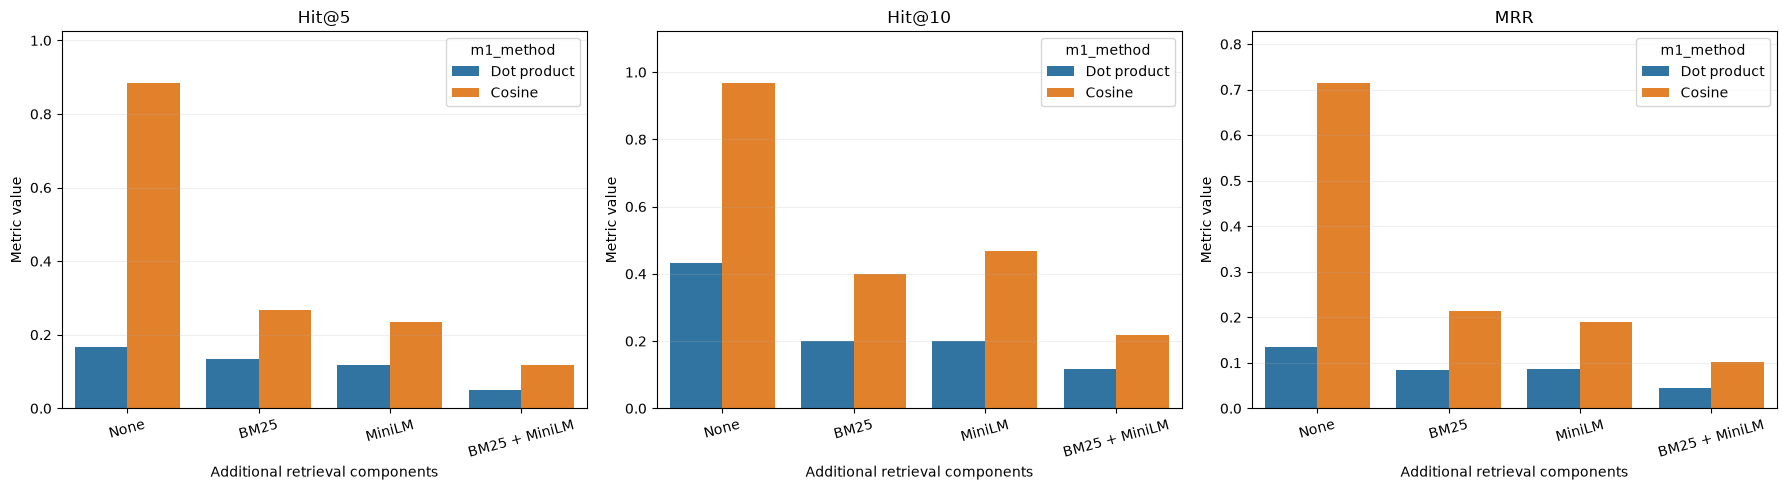

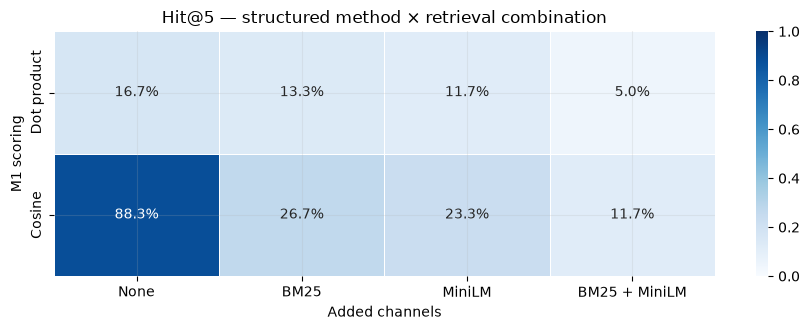

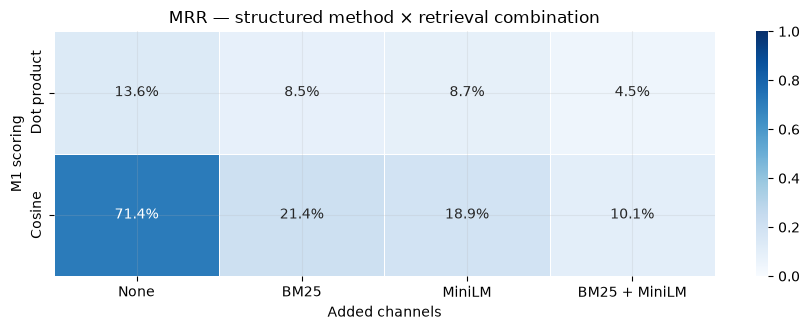

In [8]:
display(show_results(selected))
plot_grouped_metrics(selected, ("hit_at_5", "hit_at_10", "mrr"))
_ = plot_method_heatmap(selected, metric="hit_at_5")
_ = plot_method_heatmap(selected, metric="mrr")


## 5. Matched dot-product vs cosine comparisons

Only conditions present for **both** M1 scorers should be interpreted as direct method comparisons. Empty cells are intentionally preserved when a configuration hasn't been evaluated.

,metric,extras,dot,cosine,delta_cosine_minus_dot
0,Hit@1,None,3.3%,58.3%,+55.0%
1,Hit@1,BM25,1.7%,13.3%,+11.7%
2,Hit@1,MiniLM,1.7%,8.3%,+6.7%
3,Hit@1,BM25 + MiniLM,0.0%,3.3%,+3.3%
4,Hit@5,None,16.7%,88.3%,+71.7%
5,Hit@5,BM25,13.3%,26.7%,+13.3%
6,Hit@5,MiniLM,11.7%,23.3%,+11.7%
7,Hit@5,BM25 + MiniLM,5.0%,11.7%,+6.7%
8,Hit@10,None,43.3%,96.7%,+53.3%
9,Hit@10,BM25,20.0%,40.0%,+20.0%


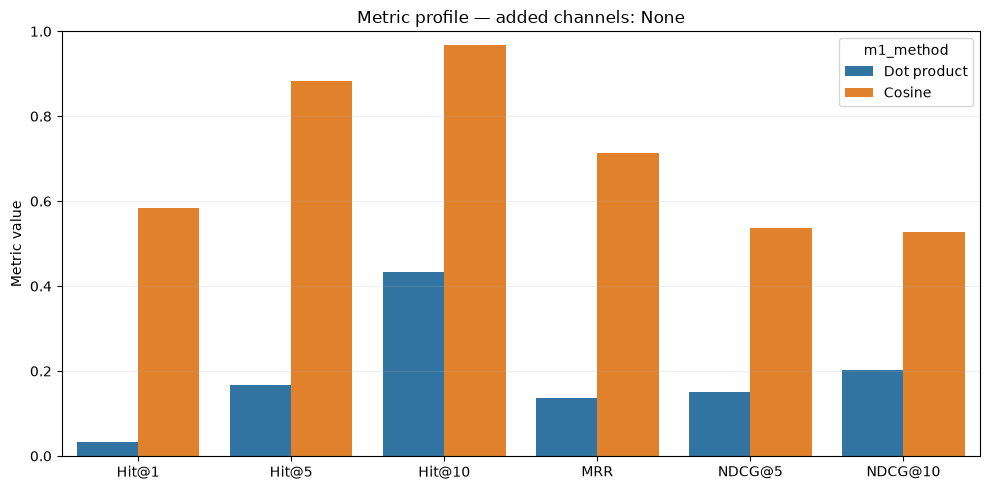

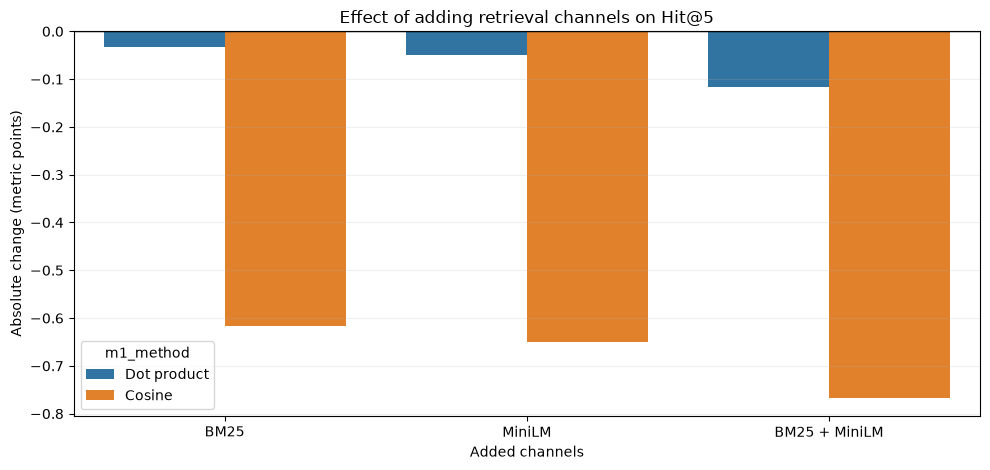

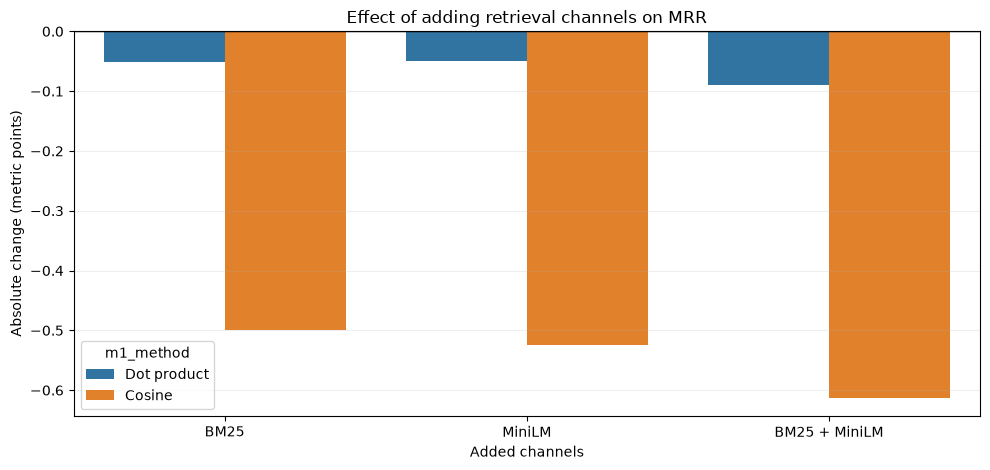

In [9]:
paired = compare_structured_methods(selected)
display(paired.style.format({"dot":"{:.1%}", "cosine":"{:.1%}", "delta_cosine_minus_dot":"{:+.1%}"}).background_gradient(subset=["delta_cosine_minus_dot"], cmap="RdYlGn", vmin=-1, vmax=1))
plot_metric_profile(selected, extras="None")
plot_fusion_impact(selected, "hit_at_5")
plot_fusion_impact(selected, "mrr")


## 6. Direct answer: which method wins in each combination?

This is a comparison of recorded aggregate metrics, not a significance test. `Winner` is meaningful only where both methods have results under matching conditions.

In [10]:
def summarize_winners(paired_df, metric="Hit@5"):
    sub = paired_df[paired_df.metric.eq(metric)].copy()
    sub["winner"] = np.select(
        [sub["dot"].isna() | sub["cosine"].isna(), sub["cosine"] > sub["dot"], sub["dot"] > sub["cosine"]],
        ["Missing pair", "Cosine", "Dot product"], default="Tie")
    return sub[["extras", "dot", "cosine", "delta_cosine_minus_dot", "winner"]]

display(summarize_winners(paired, "Hit@5").style.format({"dot":"{:.1%}","cosine":"{:.1%}","delta_cosine_minus_dot":"{:+.1%}"}))


,extras,dot,cosine,delta_cosine_minus_dot,winner
4,None,16.7%,88.3%,+71.7%,Cosine
5,BM25,13.3%,26.7%,+13.3%,Cosine
6,MiniLM,11.7%,23.3%,+11.7%,Cosine
7,BM25 + MiniLM,5.0%,11.7%,+6.7%,Cosine


## 7. Inspect other evaluation cohorts without mixing them

M6 `raw` and `active_only` reflect different query policies; compare these *within* M6 only. M5 has 2 mock profiles, so individual outcomes cause very large swings. This cell provides descriptive audit tables rather than an invalid cross-cohort leaderboard.

In [11]:
def audit_cohorts(df):
    for cohort_name, group in df.groupby("cohort", sort=False):
        print(f"\n### {cohort_name}: {len(group)} runs")
        summaries = group.groupby(["dataset_fingerprint", "candidate_count", "profile_count", "evidence_policy"], dropna=False).size().reset_index(name="runs")
        display(summaries)
        display(group[["configuration", "evidence_policy", "hit_at_5", "mrr", "report_path"]].sort_values("hit_at_5", ascending=False).head(8))

audit_cohorts(history)



### Oracle development: 16 runs


,dataset_fingerprint,candidate_count,profile_count,evidence_policy,runs
0,a8ac34541c4e07144a7133d004d2463512c328b869deaf...,378,60,raw,15
1,db255210bf9193e0f8378146b421d576f9fe2e0fe29fd9...,378,60,raw,1


,configuration,evidence_policy,hit_at_5,mrr,report_path
20,Cosine,raw,0.883333,0.713695,reports/ranking/m1_cosine/cosine
21,Cosine + BM25,raw,0.266667,0.214472,reports/ranking/m1_cosine/bm25
22,Cosine + MiniLM,raw,0.233333,0.189187,reports/ranking/m1_cosine/dense
0,Dot product,raw,0.166667,0.135636,reports/ranking/m2/baseline
19,Dot product,raw,0.166667,0.135636,reports/ranking/m1_cosine/dot_product
1,Dot product,raw,0.166667,0.135636,reports/ranking/m3/structured
4,Dot product,raw,0.166667,0.135636,reports/ranking/m4/structured
3,Dot product + BM25,raw,0.133333,0.084887,reports/ranking/m3/hybrid



### M5 mock tracker: 2 runs


,dataset_fingerprint,candidate_count,profile_count,evidence_policy,runs
0,312e2023ee6511333bbfa4c37f88d2bf3a3315f9a2c20e...,378,2,unspecified,2


,configuration,evidence_policy,hit_at_5,mrr,report_path
12,Dot product + BM25 + MiniLM,unspecified,0.5,0.527778,reports/ranking/m5/frozen/three_way_v1
11,Dot product,unspecified,0.0,0.154762,reports/ranking/m5/frozen/baseline_v1



### M6 mock stress: 6 runs


,dataset_fingerprint,candidate_count,profile_count,evidence_policy,runs
0,cb11736640cdb6b3561d2f919a222ebafd150004742080...,378,60,active_only,3
1,cb11736640cdb6b3561d2f919a222ebafd150004742080...,378,60,raw,3


,configuration,evidence_policy,hit_at_5,mrr,report_path
14,Dot product + BM25,active_only,0.150000,0.113390,reports/ranking/m6/run_v1/hybrid_active_only
16,Dot product + MiniLM,active_only,0.133333,0.111206,reports/ranking/m6/run_v1/structured_dense_act...
13,Dot product + BM25,raw,0.116667,0.081047,reports/ranking/m6/run_v1/hybrid_raw
18,Dot product + BM25 + MiniLM,active_only,0.100000,0.090324,reports/ranking/m6/run_v1/three_way_active_only
15,Dot product + MiniLM,raw,0.083333,0.095314,reports/ranking/m6/run_v1/structured_dense_raw
17,Dot product + BM25 + MiniLM,raw,0.083333,0.089772,reports/ranking/m6/run_v1/three_way_raw


## 8. Data integrity and interpretation checklist

- **Do not average repeat runs as independent evidence.** A repeated evaluation on identical inputs is not additional sample evidence.
- **Check manifests:** same dataset fingerprint and sizes are necessary but may not prove equal evaluation settings, labels, tracker modes, selection policies, and score definitions.
- **Missing pair ≠ zero performance.** Don't infer weighted-dot/BM25 superiority or inferiority without the matching experiment.
- **MRR and Hit@K** are measured on the known target occupation; they do not necessarily capture all suitable careers.
- **Cosine’s dramatic improvement warrants an implementation/label audit.** Check that oracle profile creation, candidate vectors, relevant targets, score scales, and normalization are independent and applied consistently; strong performance is not automatically evidence of leakage.
- **For statistical inference**, read compatible saved per-profile predictions and compute paired bootstrap confidence intervals or a paired randomization test. This notebook intentionally does not fabricate these from aggregate rows.

### Optional: compare custom experiments

After new runs have been appended, change `CSV_PATH` in the first code cell and **Run All**. The latest matching fingerprint is selected automatically; or set `SELECTED = {...}` with the explicit fingerprint, candidate count, and profile count to fix the cohort.